LAB 08
INSTRUCTOR ATTIQUE UR REHMAN 
NAME : ZOHA ADNAN
SAP ID: 70177706


In [1]:
import os
print(os.listdir())

['.anaconda', '.conda', '.ipynb_checkpoints', '.ipython', '.jupyter', '.keras', '3D Objects', 'AppData', 'Application Data', 'Breakout_Cleaned_Data.csv', 'Breakout_Final_Analyzed_Data.csv', 'Breakout_Pakistan_Final_Dataset.csv', 'Breakout_Pakistan_Final_Dataset.csv Lab02.ipynb', 'CNN lab07.ipynb', 'Contacts', 'Cookies', 'Demo.ipynb', 'Desktop', 'Diabetes logistic regression lab05.ipynb', 'diabetes_logistic_model.pkl', 'Digits Recognition lab08.ipynb', 'Digits Recognition.ipynb', 'Documents', 'Downloads', 'Favorites', 'images.png', 'IntelGraphicsProfiles', 'Links', 'Local Settings', 'Multiregression Lab04.ipynb', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{2e9d2b43-853a-11ed-bbdc-080027ec4824}.TM.blf', 'NTUSER.DAT{2e9d2b43-853a-11ed-bbdc-080027ec4824}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{2e9d2b43-853a-11ed-bbdc-080027ec4824}.TMContainer00000000000000000002.regtrans-ms', 'ntuser.ini', 'OneDrive', 'Pictures', 'Pr

In [2]:
%pip install tensorflow

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [3]:
import sys
print(sys.version)

3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow.keras import models, layers

In [5]:
df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")
print("Train shape:", df.shape)      # expect (42000, 785)
print("Test shape:", test_df.shape)  # expect (28000, 784)
df.head()

Train shape: (42000, 785)
Test shape: (28000, 784)


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [6]:
y = df.iloc[:, 0].values
X = df.iloc[:, 1:].values.astype("float32") / 255.0
X = X.reshape(-1, 28, 28, 1)

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, " Validation:", X_val.shape)

Train: (33600, 28, 28, 1)  Validation: (8400, 28, 28, 1)


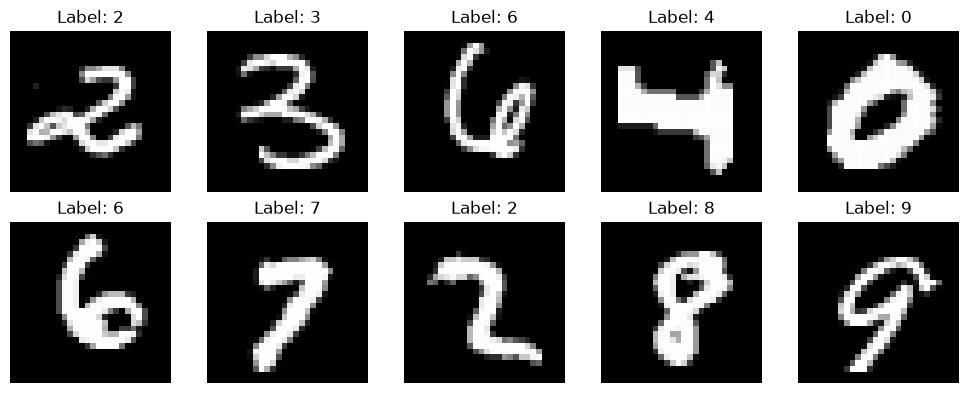

In [7]:
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap="gray")
    plt.title("Label: " + str(y_train[i]))
    plt.axis("off")
plt.tight_layout()
plt.show()

In [8]:
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3)),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3)),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128),
    layers.Activation("relu"),
    layers.Dropout(0.3),
    layers.Dense(10),
    layers.Activation("softmax"),
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation (Activation)              │ (None, 26, 26, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_1 (Activation)            │ (None, 11, 11, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_2 (Activation)            │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_3 (Activation)            │ (None, 10)                  │               0 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

In [10]:
history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=64,
    validation_data=(X_val, y_val),
)

Epoch 1/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - accuracy: 0.9218 - loss: 0.2568 - val_accuracy: 0.9746 - val_loss: 0.0826
Epoch 2/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 12s 23ms/step - accuracy: 0.9746 - loss: 0.0823 - val_accuracy: 0.9799 - val_loss: 0.0648
Epoch 3/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 12s 22ms/step - accuracy: 0.9826 - loss: 0.0575 - val_accuracy: 0.9823 - val_loss: 0.0541
Epoch 4/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.9862 - loss: 0.0461 - val_accuracy: 0.9833 - val_loss: 0.0536
Epoch 5/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.9889 - loss: 0.0354 - val_accuracy: 0.9855 - val_loss: 0.0489
Epoch 6/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - accuracy: 0.9899 - loss: 0.0306 - val_accuracy: 0.9869 - val_loss: 0.0447
Epoch 7/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.9920 - loss: 0.0256 - val_accuracy: 0.9860 - val_loss: 0.0481
Epoch 8/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.9926 - loss: 0.0227 - 

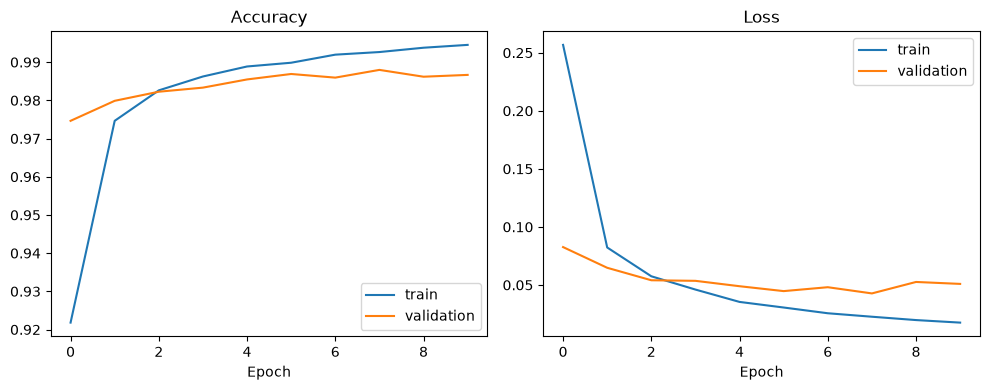

In [11]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.title("Accuracy"); plt.xlabel("Epoch"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title("Loss"); plt.xlabel("Epoch"); plt.legend()
plt.tight_layout()
plt.show()

In [12]:
X_test = test_df.values.astype("float32").reshape(-1, 28, 28, 1) / 255.0
preds = np.argmax(model.predict(X_test), axis=1)

submission = pd.DataFrame({"ImageId": np.arange(1, len(preds) + 1), "Label": preds})
submission.to_csv("submission.csv", index=False)
submission.head()

875/875 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step


,ImageId,Label
0,1,2
1,2,0
2,3,9
3,4,9
4,5,3


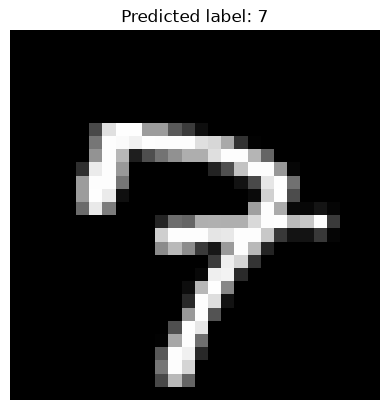

Predicted label: 7


In [14]:
X_test = (test_df.values.astype("float32") / 255.0).reshape(-1, 28, 28, 1)

idx = 5   # any image number from 0 to 27999

probs = model.predict(X_test[idx:idx+1], verbose=0)
label = np.argmax(probs)

plt.imshow(X_test[idx].reshape(28, 28), cmap="gray")
plt.title(f"Predicted label: {label}")
plt.axis("off")
plt.show()

print("Predicted label:", label)

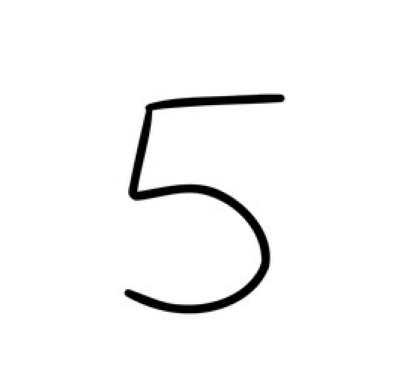

In [13]:
from PIL import Image

img = Image.open("images.png")

plt.imshow(img)
plt.axis("off")
plt.show()